# Data exploration for the deck
Two charts from the raw source files, in the same style as the Assignment 1 EDA:
1. why the label looks at the **6th monthly payment**, and
2. one **cleaning rule** carried over from Assignment 1 (income vs salary).

Reads only `data/`; saves `notebooks/figures/deck_*.png` for the slides.

In [1]:
import glob
import os
from pathlib import Path

import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datamart").exists())
FIGURES = ROOT / "notebooks" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# deck colours
NAVY, INK, BODY, MUTED, GRID = "#14213D", "#1F2933", "#4A5568", "#6B7280", "#E3E8EF"
BLUE, RUST, GREEN = "#2D72D2", "#D9773F", "#238551"
plt.rcParams.update({
    "font.family": "Calibri", "font.size": 12, "axes.edgecolor": GRID, "axes.labelcolor": BODY,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,   # gridlines behind bars and lines
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})


def save(fig, name):
    fig.savefig(FIGURES / f"deck_{name}.png", dpi=220, bbox_inches="tight")

## 1. Bad rate by month on book
Days past due (DPD) are rebuilt the same way as the silver loan table: missed instalments = overdue ÷ amount due,
and the days late are counted from the first missed due date. A loan is "bad" at a month when it is 30+ days late.

In [2]:
lms = pd.read_csv(ROOT / "data" / "lms_loan_daily.csv")
lms["snapshot_date"] = pd.to_datetime(lms["snapshot_date"])
missed = np.where(lms["overdue_amt"] > 0, np.ceil(lms["overdue_amt"] / lms["due_amt"].where(lms["due_amt"] > 0)), 0)
first_missed = [d - pd.DateOffset(months=int(m)) if m > 0 else pd.NaT for d, m in zip(lms["snapshot_date"], missed)]
dpd = (lms["snapshot_date"] - pd.Series(first_missed, index=lms.index)).dt.days.fillna(0)
lms["bad"] = (dpd >= 30).astype(int)
lms = lms[lms["installment_num"] >= 1]
by_mob = lms.groupby("installment_num")["bad"].mean()
by_mob.round(3).to_frame("share 30+ days late")

,share 30+ days late
installment_num,
1,0.051
2,0.101
3,0.170
4,0.227
5,0.283
6,0.288
7,0.288
8,0.288
9,0.288


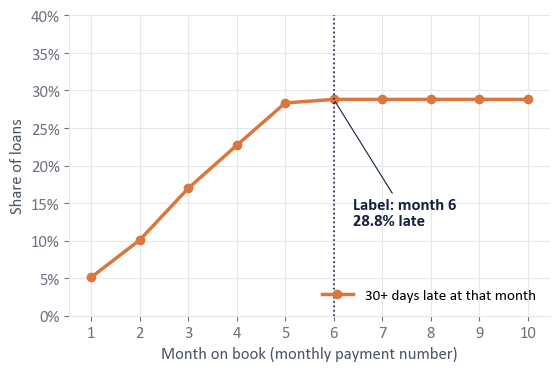

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 3.9))
ax.plot(by_mob.index, by_mob.values, color=RUST, marker="o", lw=2.5, label="30+ days late at that month")
ax.axvline(6, color=NAVY, lw=1.2, ls=":")
ax.annotate(f"Label: month 6\n{by_mob.loc[6]:.1%} late", (6, by_mob.loc[6]), xytext=(6.4, 0.12),
            color=NAVY, fontsize=12, fontweight="bold", arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
ax.set(xlabel="Month on book (monthly payment number)", ylabel="Share of loans", ylim=(0, 0.4), xticks=range(1, 11))
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.legend(loc="lower right", fontsize=11)
save(fig, "dpd_by_mob")
plt.show()

> **Takeaway:** the share of loans 30+ days late climbs over the first five payments and is flat from month 6
(28.8%). Labelling at month 6 captures nearly all early trouble while keeping the wait for an outcome short.

## 2. Cleaning rule: annual income vs monthly salary
Annual income should be about 12× the monthly in-hand salary. A small group of rows is hundreds or thousands of
times larger: data-entry errors. Assignment 1 set income to missing (and flagged it) above 30× the monthly salary.

In [4]:
fin = pd.read_csv(ROOT / "data" / "features_financials.csv")
to_number = lambda s: pd.to_numeric(s.astype(str).str.replace(r"[^0-9.]", "", regex=True), errors="coerce")
ratio = (to_number(fin["Annual_Income"]) / to_number(fin["Monthly_Inhand_Salary"])).replace([np.inf, -np.inf], np.nan).dropna()
ratio = ratio[ratio > 0]
above = (ratio > 30).mean()
print(f"rows: {len(ratio):,}; above 30x: {above:.1%}")

rows: 12,500; above 30x: 0.9%


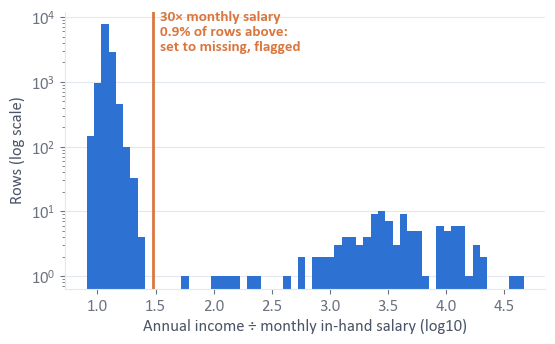

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.hist(np.log10(ratio), bins=60, color=BLUE, log=True)
ax.axvline(np.log10(30), color=RUST, lw=2)
ax.text(np.log10(30) + 0.06, ax.get_ylim()[1] * 0.25, f"30× monthly salary\n{above:.1%} of rows above:\nset to missing, flagged",
        color=RUST, fontsize=11, fontweight="bold")
ax.set(xlabel="Annual income ÷ monthly in-hand salary (log10)", ylabel="Rows (log scale)")
ax.grid(axis="x", visible=False)
save(fig, "income_rule")
plt.show()

> **Takeaway:** normal rows sit close to 12× (log10 ≈ 1.1); the corrupted rows start above 300× (log10 2.5 and
beyond), so the 30× line separates them cleanly. The rule is applied the same way every month; the threshold was
chosen by looking at the whole file, which the deck states as an assumption.